In [1]:
import sys
import pandas as pd
import importlib

sys.path.append("../src/rnacorex")

from rnacorex import RNACOREX

data_train = pd.read_csv(f"../GPB/Data/train_brca_lognorm.csv", index_col=0)
data_test = pd.read_csv(f"../GPB/Data/test_brca_lognorm.csv", index_col=0)

X_train = data_train.drop("Class", axis=1)
y_train = data_train["Class"]
X_test = data_test.drop("Class", axis=1)
y_test = data_test["Class"]

In [ ]:
# Train a model with 40 interactions.

rnacorex = RNACOREX(
        n_con=40
    )

rnacorex.fit(X_train, y_train)

# Train models from 20 to 40 interactions.

rnacorex_multi = RNACOREX.RNACOREX(
        n_con=(20, 40)
    )

rnacorex_multi.fit(X_train, y_train)

# Train models with 20 and 40 interactions.

rnacorex_multi2 = RNACOREX.RNACOREX(
        n_con=[20, 40]
    )

rnacorex_multi2.fit(X_train, y_train)


USING DEFAULT ENGINE


Fitting models: 100%|██████████| 1/1 [00:00<00:00,  8.33model/s]


,n_con,40
,precision,10
,model,'LGBN'
,mirna,True
,mrna,True
,lncrna,True
,engine,None
,mode,'alternating'
,weight,0.5
,ties,'isolated'
Name,Type,Value


In [3]:
# PREDICTION WITH COMPLETE EVIDENCE

rl = rnacorex.predict(X_test)

# PREDICTION WITH PARTIAL EVIDENCE

X_test_partial = X_test.sample(frac=0.9, axis=1, random_state=42)

rl_part = rnacorex.predict(X_test_partial)

Predicting: 100%|██████████| 1/1 [00:00<00:00, 10.07model/s]


K: 40  Predicting with complete evidence.


Predicting: 100%|██████████| 1/1 [00:00<00:00, 88.99model/s]

K: 40  Predicting with partial evidence.


In [5]:
# GET INTERACTIONS

rnacorex.get_interactions(20)

,Node1,Node2,Type1,Type2,SMI,FMI
0,hsa-mir-429,LMO7,miRNA,mRNA,0.981076,0.047948
1,COL4A1,COL4A2,mRNA,mRNA,0.000100,1.175261
2,hsa-mir-429,TGFBI,miRNA,mRNA,0.981076,0.045414
3,LAMA4,NID2,mRNA,mRNA,0.000100,1.141954
4,hsa-mir-421,HMGA2,miRNA,mRNA,0.981076,0.047236
5,SAA1,SAA2,mRNA,mRNA,0.000100,0.850799
6,hsa-mir-592,LDLR,miRNA,mRNA,0.981076,0.031802
7,C1QA,C1QC,mRNA,mRNA,0.000100,0.727701
8,hsa-mir-2110,TRA2A,miRNA,mRNA,0.981076,0.040435
9,COL4A1,NID2,mRNA,mRNA,0.000100,0.533485


In [8]:
# GET FITTED MODEL

model = rnacorex.models_[40]

# WHEN MORE THAN ONE MODEL HAS BEEN FITTED, YOU CAN ACCESS THE CORRESPONDING DATA BY SELECTING THE NUMBER OF INTERACTIONS

# model25 = rnacorex_multi.models_[25]

# model35 = rnacorex_multi.models_[35]

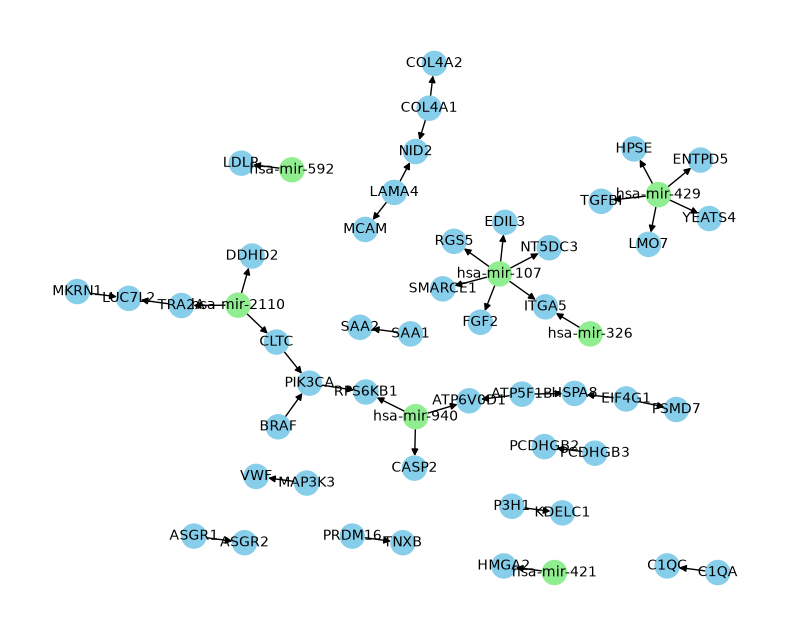

,n_con,40
,precision,10
,model,'LGBN'
,mirna,True
,mrna,True
,lncrna,True
,engine,None
,mode,'alternating'
,weight,0.5
,ties,'isolated'
Name,Type,Value


In [11]:
# RAW NETWORK

G = rnacorex.model_['G']

rnacorex.display(G)

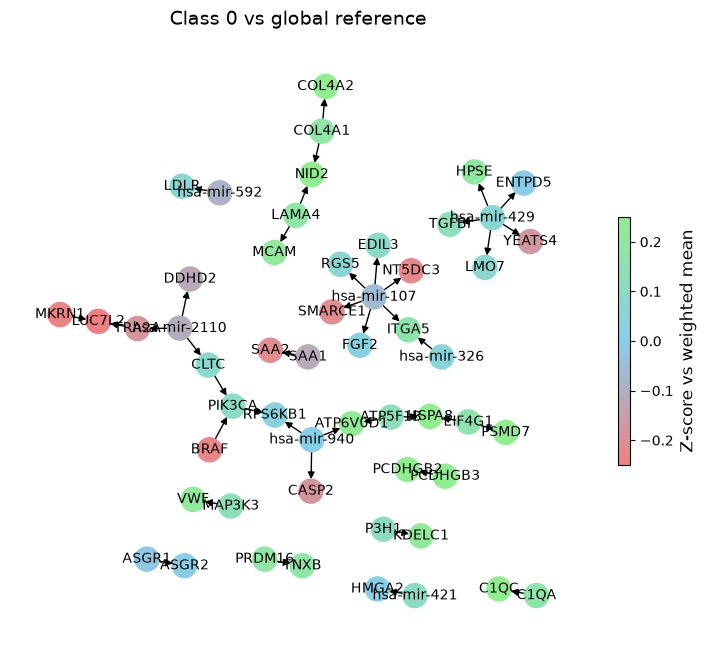

In [12]:
# MPC NETWORK

maps = rnacorex.mpc(
    display=True,             
    c=0,                
    k=40,
    th=0.25
)